In [ ]:
# AI That Detects Fake Job and Internship Offers

print("AI Fake Job and Internship Detection Project")
print("Project setup started successfully!")

AI Fake Job and Internship Detection Project
Project setup started successfully!


In [ ]:

# Step 1: Import libraries and load the dataset

import pandas as pd
import numpy as np
import csv

file_path = '/content/fake_job_postings.csv'

# Read CSV using Python engine
df = pd.read_csv(
    file_path,
    engine='python',
    on_bad_lines='warn'
)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Columns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())


Dataset loaded successfully!
Dataset Shape: (17880, 18)

First 5 Records:


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0



Dataset Columns:
['job_id', 'title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent']

Missing Values:
job_id                     0
title                      0
location                 346
department             11547
salary_range           15012
company_profile         3308
description                1
requirements            2696
benefits                7212
telecommuting              0
has_company_logo           0
has_questions              0
employment_type         3471
required_experience     7050
required_education      8105
industry                4903
function                6455
fraudulent                 0
dtype: int64


In [ ]:

# Step 2: Check genuine and fake job postings

print("Job Posting Distribution:")

print(df['fraudulent'].value_counts())

print("\nPercentage Distribution:")

print(df['fraudulent'].value_counts(normalize=True) * 100)


Job Posting Distribution:
fraudulent
0    17014
1      866
Name: count, dtype: int64

Percentage Distribution:
fraudulent
0    95.1566
1     4.8434
Name: proportion, dtype: float64


In [ ]:

# Step 3: Data Cleaning and Preprocessing

# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Fill missing text values with empty strings
text_columns = [
    'title',
    'company_profile',
    'description',
    'requirements',
    'benefits'
]

for column in text_columns:
    df[column] = df[column].fillna('')

# Remove duplicate records
df = df.drop_duplicates()

# Remove records with missing target values
df = df.dropna(subset=['fraudulent'])

# Convert target column to integer
df['fraudulent'] = df['fraudulent'].astype(int)

print("\nData cleaning completed!")
print("Dataset shape after cleaning:", df.shape)

print("\nMissing values after cleaning:")
print(df[text_columns].isnull().sum())


Missing values before cleaning:
job_id                     0
title                      0
location                 346
department             11547
salary_range           15012
company_profile         3308
description                1
requirements            2696
benefits                7212
telecommuting              0
has_company_logo           0
has_questions              0
employment_type         3471
required_experience     7050
required_education      8105
industry                4903
function                6455
fraudulent                 0
dtype: int64

Data cleaning completed!
Dataset shape after cleaning: (17880, 18)

Missing values after cleaning:
title              0
company_profile    0
description        0
requirements       0
benefits           0
dtype: int64


In [ ]:

# Step 4: Combine important job information

df['job_text'] = (
    df['title'] + ' ' +
    df['company_profile'] + ' ' +
    df['description'] + ' ' +
    df['requirements'] + ' ' +
    df['benefits']
)

# Remove extra spaces
df['job_text'] = df['job_text'].str.strip()

# Remove records with empty job information
df = df[df['job_text'] != ''].copy()

print("Job information combined successfully!")

print("\nSample job description:")
print(df['job_text'].iloc[0])

print("\nFinal dataset shape:", df.shape)


Job information combined successfully!

Sample job description:
Marketing Intern We're Food52, and we've created a groundbreaking and award-winning cooking site. We support, connect, and celebrate home cooks, and give them everything they need in one place.We have a top editorial, business, and engineering team. We're focused on using technology to find new and better ways to connect people around their specific food interests, and to offer them superb, highly curated information about food and cooking. We attract the most talented home cooks and contributors in the country; we also publish well-known professionals like Mario Batali, Gwyneth Paltrow, and Danny Meyer. And we have partnerships with Whole Foods Market and Random House.Food52 has been named the best food website by the James Beard Foundation and IACP, and has been featured in the New York Times, NPR, Pando Daily, TechCrunch, and on the Today Show.We're located in Chelsea, in New York City. Food52, a fast-growing, James Bea

In [ ]:

# Step 5: Text Vectorization using TF-IDF

from sklearn.feature_extraction.text import TfidfVectorizer

# Convert job text into numerical features
tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=10000,
    ngram_range=(1, 2)
)

X = tfidf.fit_transform(df['job_text'])
y = df['fraudulent']

print("TF-IDF conversion completed!")
print("Feature matrix shape:", X.shape)
print("Target variable shape:", y.shape)


TF-IDF conversion completed!
Feature matrix shape: (17880, 10000)
Target variable shape: (17880,)


In [ ]:

# Step 6: Split dataset into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dataset splitting completed!")
print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])


Dataset splitting completed!
Training records: 14304
Testing records: 3576


In [ ]:

# Step 7: Train the Logistic Regression model

from sklearn.linear_model import LogisticRegression

# Create the model
model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Machine Learning Model trained successfully!")


Machine Learning Model trained successfully!


Model Accuracy: 97.51 %

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      3403
           1       0.68      0.90      0.78       173

    accuracy                           0.98      3576
   macro avg       0.84      0.94      0.88      3576
weighted avg       0.98      0.98      0.98      3576



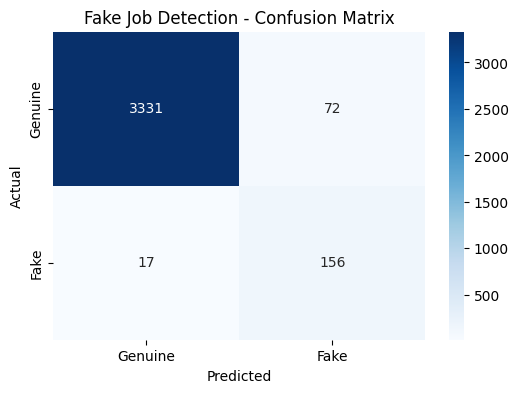

In [ ]:

# Step 8: Evaluate model performance

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

# Make predictions
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Display confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Genuine', 'Fake'],
    yticklabels=['Genuine', 'Fake']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Fake Job Detection - Confusion Matrix")
plt.show()


In [ ]:

# Step 9: Save the trained AI model

import joblib
import os

# Create model folder
os.makedirs('/content/model', exist_ok=True)

# Save model and TF-IDF vectorizer together
joblib.dump(
    {
        'model': model,
        'tfidf': tfidf
    },
    '/content/model/fake_job_model.pkl'
)

print("Model saved successfully!")
print("File: fake_job_model.pkl")


Model saved successfully!
File: fake_job_model.pkl


In [ ]:

# Step 10: Download the trained model

from google.colab import files

files.download('/content/model/fake_job_model.pkl')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

%%writefile /content/app.py

import streamlit as st
import joblib
import re
import os

# Page configuration
st.set_page_config(
    page_title="AI Fake Job Detector",
    page_icon="🔍",
    layout="wide"
)

# Load trained model
MODEL_PATH = "/content/model/fake_job_model.pkl"

@st.cache_resource
def load_model():
    return joblib.load(MODEL_PATH)

bundle = load_model()
model = bundle["model"]
tfidf = bundle["tfidf"]

# Custom website styling
st.markdown("""
<style>
.main {
    background-color: #f5f7fb;
}
.main-title {
    text-align: center;
    color: #17365D;
    font-size: 38px;
    font-weight: bold;
}
.subtitle {
    text-align: center;
    color: #555;
    font-size: 17px;
}
.result {
    padding: 20px;
    border-radius: 12px;
    text-align: center;
    font-size: 25px;
    font-weight: bold;
}
</style>
""", unsafe_allow_html=True)

# Website heading
st.markdown(
    '<div class="main-title">🔍 AI Fake Job & Internship Detector</div>',
    unsafe_allow_html=True
)

st.markdown(
    '<div class="subtitle">Use Artificial Intelligence to identify potentially fraudulent job offers.</div>',
    unsafe_allow_html=True
)

st.write("")
st.divider()

# Project information
col1, col2, col3 = st.columns(3)

col1.metric("Technology", "Machine Learning")
col2.metric("Algorithm", "Logistic Regression")
col3.metric("Text Processing", "TF-IDF")

st.divider()

# User input
st.subheader("📋 Analyse a Job or Internship Offer")

job_description = st.text_area(
    "Paste the complete job or internship description below:",
    height=250,
    placeholder="Enter job title, company details, salary, requirements and job description..."
)

# Prediction button
if st.button("🔍 Analyse Offer", use_container_width=True):

    if len(job_description.strip()) < 30:
        st.warning("Please enter a more detailed job or internship description.")

    else:
        # Convert text using the trained TF-IDF vectorizer
        input_vector = tfidf.transform([job_description])

        # Predict result
        prediction = model.predict(input_vector)[0]

        # Get prediction probabilities
        probabilities = model.predict_proba(input_vector)[0]
        fake_index = list(model.classes_).index(1)
        fake_probability = probabilities[fake_index] * 100

        st.divider()
        st.subheader("📊 Analysis Result")

        if prediction == 1:
            st.error("⚠️ This job posting is predicted to be POTENTIALLY FRAUDULENT.")
        else:
            st.success("✅ This job posting is predicted to be LIKELY GENUINE.")

        st.metric(
            "Model-estimated fraud probability",
            f"{fake_probability:.2f}%"
        )

        st.progress(float(fake_probability / 100))

        st.caption(
            "This percentage is the model's estimated probability, "
            "not a guarantee that the offer is fake or genuine."
        )

        # Basic warning-sign checks
        warning_patterns = {
            "Requests for payment": r"\b(registration fee|processing fee|security deposit|pay upfront|training fee)\b",
            "Unusually high salary claims": r"\b(easy money|earn lakhs|high income guaranteed|guaranteed income)\b",
            "Requests for personal or banking details": r"\b(bank details|credit card|otp|password)\b",
            "Urgent pressure": r"\b(apply immediately|limited vacancies|urgent hiring|act now)\b"
        }

        found_warnings = []

        for warning, pattern in warning_patterns.items():
            if re.search(pattern, job_description, re.IGNORECASE):
                found_warnings.append(warning)

        st.subheader("🚩 Potential Warning Signs")

        if found_warnings:
            for warning in found_warnings:
                st.warning(warning)
        else:
            st.info("No warning phrases from our basic checklist were detected.")

        st.subheader("🛡️ Safety Recommendations")

        st.write("""
        - Verify the company through its official website.
        - Check whether the recruiter uses an official company email address.
        - Never pay money to secure a job or internship.
        - Do not share OTPs, passwords or banking credentials.
        - Verify the offer independently before accepting it.
        """)

st.divider()

st.caption(
    "AI Fake Job and Internship Detector | Academic Machine Learning Project"
)
st.caption(
    "Disclaimer: Predictions are based on patterns learned from the training dataset. "
    "Always independently verify job offers."
)




Writing /content/app.py


In [ ]:

%%writefile /content/requirements.txt

streamlit
pandas
numpy
scikit-learn
joblib


Writing /content/requirements.txt


In [ ]:
MODEL_PATH = "/content/model/fake_job_model.pkl"

In [ ]:
import os

MODEL_PATH = os.path.join(
    "/content",
    "model",
    "fake_job_model.pkl"
)

print("Model path:", MODEL_PATH)
print("Model exists:", os.path.exists(MODEL_PATH))

Model path: /content/model/fake_job_model.pkl
Model exists: True


In [ ]:
import os

MODEL_PATH = "/content/model/fake_job_model.pkl"

print("Model path:", MODEL_PATH)
print("Model exists:", os.path.exists(MODEL_PATH))

Model path: /content/model/fake_job_model.pkl
Model exists: True


In [ ]:
import joblib

model = joblib.load("/content/model/fake_job_model.pkl")

print("Model loaded successfully!")
print("Model type:", type(model))

Model loaded successfully!
Model type: <class 'dict'>


In [ ]:
import joblib

model_data = joblib.load("/content/model/fake_job_model.pkl")

print("Keys available in model:")
print(model_data.keys())

print("\nDetails of each item:")

for key, value in model_data.items():
    print(key, ":", type(value))

Keys available in model:
dict_keys(['model', 'tfidf'])

Details of each item:
model : <class 'sklearn.linear_model._logistic.LogisticRegression'>
tfidf : <class 'sklearn.feature_extraction.text.TfidfVectorizer'>


In [ ]:

%%writefile /content/app.py

import os
import joblib
import streamlit as st

# Page configuration
st.set_page_config(
    page_title="AI Fake Job Detector",
    page_icon="🛡️",
    layout="wide"
)

# Load trained model
MODEL_PATH = os.path.join(
    os.path.dirname(__file__),
    "model",
    "fake_job_model.pkl"
)

model_data = joblib.load(MODEL_PATH)

model = model_data["model"]
tfidf = model_data["tfidf"]

# Custom CSS
st.markdown("""
<style>
.main {
    background-color: #f5f7fb;
}
.title {
    text-align: center;
    color: #17365D;
    font-size: 38px;
    font-weight: bold;
}
.subtitle {
    text-align: center;
    color: #555;
    font-size: 17px;
}
.stButton>button {
    background-color: #17365D;
    color: white;
    border-radius: 8px;
    height: 48px;
    width: 100%;
    font-size: 18px;
}
</style>
""", unsafe_allow_html=True)

# Header
st.markdown(
    '<div class="title">🛡️ AI Fake Job Detector</div>',
    unsafe_allow_html=True
)

st.markdown(
    '<div class="subtitle">Detect fraudulent job and internship offers using Artificial Intelligence</div>',
    unsafe_allow_html=True
)

st.write("")
st.divider()

# Information
st.subheader("🔍 Analyze a Job Posting")

st.write(
    "Enter the job information below to check whether "
    "the job posting is genuine or potentially fraudulent."
)

# Input fields
title = st.text_input("Job Title")

company_profile = st.text_area(
    "Company Profile",
    placeholder="Enter information about the company..."
)

description = st.text_area(
    "Job Description",
    placeholder="Enter the complete job description...",
    height=180
)

requirements = st.text_area(
    "Job Requirements",
    placeholder="Enter the required skills and qualifications..."
)

benefits = st.text_area(
    "Benefits",
    placeholder="Enter salary, incentives and other benefits..."
)

st.write("")

# Detection button
if st.button("🔍 Detect Fake Job"):

    if not description.strip():
        st.warning("Please enter the job description first.")

    else:
        # Combine text in the SAME order as training
        job_text = (
            title + " " +
            company_profile + " " +
            description + " " +
            requirements + " " +
            benefits
        )

        # Convert text into numerical features
        transformed_text = tfidf.transform([job_text])

        # Make prediction
        prediction = model.predict(transformed_text)[0]

        # Calculate probability
        probabilities = model.predict_proba(transformed_text)[0]

        fake_index = list(model.classes_).index(1)
        fake_probability = probabilities[fake_index] * 100

        st.divider()
        st.subheader("📊 Detection Result")

        if prediction == 1:

            st.error("⚠️ This job posting is predicted to be FAKE!")

            st.metric(
                "Estimated Fake Probability",
                f"{fake_probability:.2f}%"
            )

            st.warning(
                "Be careful. Verify the company and offer "
                "before sharing personal information or making payments."
            )

        else:

            st.success("✅ This job posting is predicted to be GENUINE!")

            st.metric(
                "Estimated Fake Probability",
                f"{fake_probability:.2f}%"
            )

            st.info(
                "The model classified this posting as genuine. "
                "Always verify the employer independently."
            )

st.divider()

# Footer
st.markdown(
    "<center>AI Fake Job Detector | Machine Learning Project</center>",
    unsafe_allow_html=True
)


Overwriting /content/app.py


In [ ]:
import os
import py_compile

app_path = "/content/app.py"

if os.path.exists(app_path):
    py_compile.compile(app_path, doraise=True)
    print("App.py syntax is correct!")

if os.path.exists("/content/model/fake_job_model.pkl"):
    print("Machine learning model found!")

if os.path.exists("/content/requirements.txt"):
    print("Requirements file found!")

App.py syntax is correct!
Machine learning model found!
Requirements file found!


In [ ]:

import os
import shutil
import zipfile

# Create project folder
project = "/content/AI-Fake-Job-Detector"

os.makedirs(project + "/model", exist_ok=True)

# Copy application files
shutil.copy("/content/app.py", project + "/app.py")
shutil.copy("/content/requirements.txt", project + "/requirements.txt")
shutil.copy("/content/fake_job_postings.csv",
            project + "/fake_job_postings.csv")

# Copy trained model
shutil.copy(
    "/content/model/fake_job_model.pkl",
    project + "/model/fake_job_model.pkl"
)

# Create README
readme = """
# AI Fake Job and Internship Detector

An AI-powered web application that detects potentially
fraudulent job and internship postings.

## Technologies Used
- Python
- Machine Learning
- Logistic Regression
- TF-IDF
- Streamlit
- Scikit-learn

## How to Run

1. Install the required packages:
   pip install -r requirements.txt

2. Start the application:
   streamlit run app.py
"""

with open(project + "/README.md", "w") as f:
    f.write(readme)

# Create ZIP file
zip_path = "/content/AI-Fake-Job-Detector.zip"

shutil.make_archive(
    "/content/AI-Fake-Job-Detector",
    "zip",
    project
)

print("Project ZIP created successfully!")
print("Location:", zip_path)



Project ZIP created successfully!
Location: /content/AI-Fake-Job-Detector.zip


In [ ]:
from google.colab import files

files.download("/content/AI-Fake-Job-Detector.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>